# Figure 2 — Comparison of classical and quantum models

* **(a, c, e)** Classical point-charge trajectories: energy change $\Delta E/\hbar\omega$ versus time for an ensemble
  of initial phase offsets $\chi\in[0,2\pi]$ (Newtonian integration of the longitudinal equation of motion).
* **(b, d, f)** Quantum sideband probabilities $P_\ell(\zeta)$ for the same parameters
  (transfer-matrix propagation, `pinem_recoil.propagate_steps`).

Rows: initial electron velocity $v_0 = v_{\rm ph}\times\{1,\ 0.998,\ 0.995\}$ (velocity mismatch
$\delta_v=v_0/v_{\rm ph}-1=0,\ -0.2\,\%,\ -0.5\,\%$, Eq. (6) of the paper), 532 nm light, field amplitude $E_0=4$ MV/m (the real field is $2E_0\cos(\dots)$),
phase velocity set by total internal reflection in a prism of index $n=3.55$ at $60^\circ$ incidence
(electron energy ≈ 29.4 keV).

**Data files** (plain-text CSV, see `data/README.md`): `data/fig2/fig2a_dE.csv`, `fig2c_dE.csv`, `fig2e_dE.csv`
(classical energy change, rows: time in fs, columns: initial phase $\chi$), `data/fig2/fig2b_P.csv`, `fig2d_P.csv`,
`fig2f_P.csv` (sideband maps, rows $\ell$, columns $\zeta$), `data/fig2/fig2_rows.csv` ($v_0/v_{\rm ph}$, $a$, $g$ of each row)
and `data/fig2/fig2_parameters.csv`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.constants import hbar, e, m_e, c
import pinem_recoil as pr

DATA = Path("data") / "fig2"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False

## Parameters

In [2]:
wavelength = 532e-9
n_prism = 3.55
theta_inc = np.radians(60)
omega = 2 * np.pi * c / wavelength
k_par = n_prism * (2 * np.pi / wavelength) * np.sin(theta_inc)   # parallel wave vector
v_ph = omega / k_par                                              # phase velocity
E_field = 2 * 4e6          # amplitude of the real field 2*E0*cos(...), E0 = 4 MV/m

t_max = 1000e-15           # classical integration time
dt = 1e-16                 # classical time step
n_steps = int(t_max / dt)
t = np.linspace(0, t_max, n_steps)     # time axis used for plotting
n_phases = 51
phases = np.linspace(0, 2 * np.pi, n_phases)   # initial phase offsets chi
v0_over_vph = np.array([1.0, 0.998, 0.995])    # rows of the figure

zeta_max = int(t_max * omega)    # quantum propagation distance matching t_max
d_zeta = 1

gamma_ph = 1 / np.sqrt(1 - (v_ph / c)**2)
print(f"phase velocity v_ph = {v_ph:.4e} m/s = {v_ph/c:.4f} c;  "
      f"phase-matched kinetic energy = {(gamma_ph - 1) * m_e * c**2 / e / 1e3:.2f} keV")

phase velocity v_ph = 9.7513e+07 m/s = 0.3253 c;  phase-matched kinetic energy = 29.39 keV


## Computation

Classical model: $m_e\ddot z = eE(z,t)$ with $E=2E_0\cos(k_\parallel z-\omega t+\chi)$, integrated with a
semi-implicit Euler scheme (all phases are propagated simultaneously). The quantum parameters $a$ and $g$ are
derived from the electron velocity; the truncation $\ell_{\max}$ is chosen from the classical energy range.

In [3]:
def classical_energies(v0):
    """Kinetic energy (in units of hbar*omega) for every phase and time step."""
    z = np.zeros(n_phases)
    v = np.full(n_phases, v0)
    energies = np.zeros((n_phases, n_steps))
    for i in range(n_steps):
        accel = (e / m_e) * E_field * np.cos(k_par * z - omega * t[i] + phases)
        v = v + accel * dt
        z = z + v * dt
        energies[:, i] = 0.5 * m_e * v**2 / (hbar * omega)
    return energies, v[-1]   # final velocity of the last trajectory


files_cl = [DATA / f"fig2{p}_dE.csv" for p in "ace"]
files_q = [DATA / f"fig2{p}_P.csv" for p in "bdf"]
file_rows = DATA / "fig2_rows.csv"
file_par = DATA / "fig2_parameters.csv"
if RECOMPUTE or not all(f.exists() for f in [*files_cl, *files_q, file_rows, file_par]):
    dE = np.zeros((3, n_phases, n_steps))
    P, ell_axes, a_vals, g_vals = [], [], [], []
    for k, ratio in enumerate(v0_over_vph):
        v0 = v_ph * ratio
        energies, v_end = classical_energies(v0)
        E_kin0 = 0.5 * m_e * v0**2 / (hbar * omega)
        dE[k] = energies - E_kin0
        # quantum parameters (velocity of the last trajectory at the end of the
        # classical run is used for g and gamma, as in the original calculation)
        g = e * v_end * E_field / (2 * hbar * omega**2)
        gamma = 1 / np.sqrt(1 - (v_end / c)**2)
        a = 2 * m_e * v0**2 * gamma**3 / (hbar * omega)
        l_max = int(np.max(dE[k]) + 10)
        d_phi = -d_zeta * (2 - ratio)          # = -d_zeta * v_ph / v0 to first order
        zeta, phi = pr.propagate_steps(a, g, l_max, d_zeta, d_phi, zeta_max)
        P.append(np.abs(phi)**2)
        ell_axes.append(pr.sideband_axis(l_max))
        a_vals.append(a); g_vals.append(g)
        print(f"v0/v_ph = {ratio}:  a = {a:.0f},  g = {g:.3f},  l_max = {l_max}")
    for k in range(3):
        pr.save_map(files_cl[k], dE[k].T, phases, t * 1e15, "chi_rad", "t_fs")
        pr.save_map(files_q[k], P[k], zeta, ell_axes[k], "zeta", "ell")
    pr.save_columns(file_rows, panels=["a+b", "c+d", "e+f"], v0_over_vph=v0_over_vph,
                    delta_v=v0_over_vph - 1,
                    a=a_vals, g=g_vals, l_max=[len(e_) // 2 for e_ in ell_axes])
    pr.save_parameters(file_par, [
        ("wavelength_m", wavelength, "light wavelength"),
        ("n_prism", n_prism, "refractive index of the prism"),
        ("incidence_angle_deg", 60, "angle of incidence (total internal reflection)"),
        ("v_ph_m_per_s", v_ph, "phase velocity of the evanescent field"),
        ("E_field_V_per_m", E_field, "amplitude of the real field 2 E0 cos(...) (E0 = 4 MV/m)"),
        ("dt_s", dt, "time step of the classical integration"),
        ("d_zeta", d_zeta, "propagation step of the quantum calculation"),
        ("d_phi", "-d_zeta*(2 - v0/v_ph)", "field-phase step per propagation step"),
    ])
    print("saved", *files_cl, *files_q, file_rows, file_par)

## Load data and plot

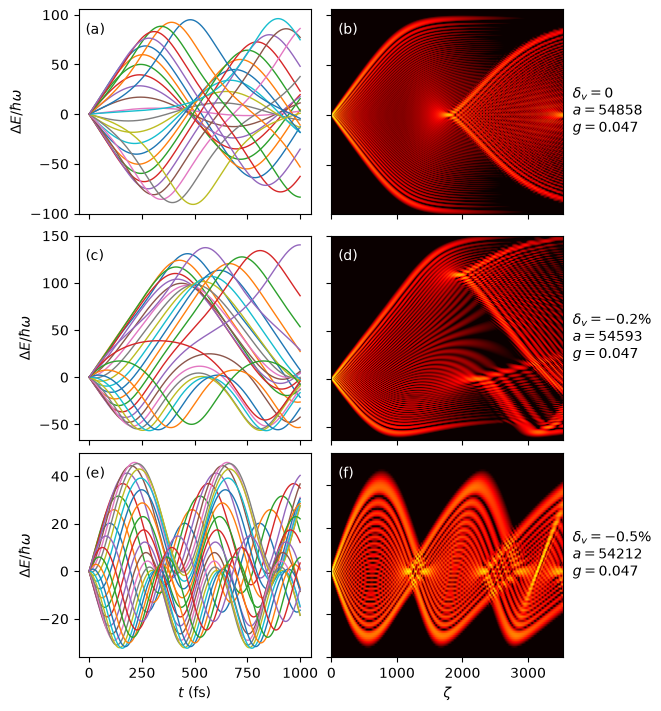

In [4]:
rows = pr.load_columns(file_rows)
cl = [pr.load_map(f) for f in files_cl]     # (chi, t_fs, dE[i_t, i_chi])
q = [pr.load_map(f) for f in files_q]       # (zeta, ell, P[i_ell, i_zeta])

cmap = plt.get_cmap("hot").copy()
cmap.set_under(cmap(0.0)); cmap.set_bad(cmap(0.0))
row_labels = [rf"$\delta_v={dv * 100:.1f}\%$" if dv else r"$\delta_v=0$" for dv in rows["delta_v"]]

fig, ax = plt.subplots(3, 2, figsize=(6.5, 7), constrained_layout=True)
for k in range(3):
    chi, t_fs, dE = cl[k]
    dE = dE.T                                    # dE[i_chi, i_t]
    for j in range(0, n_phases - 1, 2):          # every second phase is plotted
        ax[k, 0].plot(t_fs, dE[j], lw=1)
    ax[k, 0].set_ylabel(r"$\Delta E/\hbar\omega$")
    ax[k, 0].text(0.03, 0.88, "(" + "ace"[k] + ")", transform=ax[k, 0].transAxes)

    zeta, ell, P = q[k]
    lo, hi = int(np.min(dE)) - 10 + 2, int(np.max(dE)) + 10
    ax[k, 1].imshow(P, aspect="auto", origin="lower", cmap=cmap,
                    norm=LogNorm(vmin=1e-3, vmax=1),
                    extent=[zeta[0] - 0.5, zeta[-1] + 0.5, ell[0] - 0.5, ell[-1] + 0.5])
    ax[k, 1].set_ylim(lo, hi)
    ax[k, 1].set_yticklabels([])
    ax[k, 1].text(0.03, 0.88, "(" + "bdf"[k] + ")", color="w", transform=ax[k, 1].transAxes)
    ax[k, 1].text(1.04, 0.5, row_labels[k] + "\n" + rf"$a={rows['a'][k]:.0f}$" + "\n" + rf"$g={rows['g'][k]:.3f}$",
                  transform=ax[k, 1].transAxes, va="center")
for k in range(2):
    ax[k, 0].set_xticklabels([]); ax[k, 1].set_xticklabels([])
ax[2, 0].set_xlabel(r"$t$ (fs)")
ax[2, 1].set_xlabel(r"$\zeta$")
fig.savefig(FIGS / "fig2.png", dpi=200)
fig.savefig(FIGS / "fig2.pdf")
plt.show()